# Exploratory Data Analysis — Online Retail II

## Project: EconoCausal — Dynamic Pricing via Double Machine Learning

**Team:** Group 22

**Purpose:** Inspect data quality, missing values, exact duplicates, and price/quantity distributions before selecting a sample for causal analysis.

**Important:** This notebook does not modify the raw dataset. No causal model is trained here.


## 1. Imports and Dataset Loading

Load both worksheets and validate the expected columns.


In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data" / "raw" / "online_retail_II.xlsx").exists():
    ROOT = Path.cwd().parent

DATA_FILE = ROOT / "data" / "raw" / "online_retail_II.xlsx"
SHEETS = ["Year 2009-2010", "Year 2010-2011"]
EXPECTED_COLUMNS = [
    "Invoice", "StockCode", "Description", "Quantity",
    "InvoiceDate", "Price", "Customer ID", "Country"
]

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_FILE}. Place the file in data/raw/."
    )

frames = {}
for sheet in SHEETS:
    frames[sheet] = pd.read_excel(
        DATA_FILE, sheet_name=sheet, engine="openpyxl"
    )
    frames[sheet].columns = frames[sheet].columns.astype(str).str.strip()
    missing = set(EXPECTED_COLUMNS) - set(frames[sheet].columns)
    if missing:
        raise ValueError(f"{sheet} is missing columns: {sorted(missing)}")

df = pd.concat(frames.values(), ignore_index=True)

print("Dataset loaded successfully")
print("Worksheet rows:", {name: len(frame) for name, frame in frames.items()})
print("Combined shape:", df.shape)
display(df.head())


Dataset loaded successfully
Worksheet rows: {'Year 2009-2010': 525461, 'Year 2010-2011': 541910}
Combined shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 2. Schema and Data Types

Inspect column types and summary statistics. Mixed data types and extreme values require further investigation rather than automatic removal.


In [16]:
display(df.dtypes.rename("data_type").to_frame())
display(df.describe(include="all").T)


,data_type
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
Price,float64
Customer ID,float64
Country,str


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,1067371.0,53628.0,537434.0,1350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1067371.0,NaN,NaN,NaN,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,NaN,NaN,NaN,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
Customer ID,824364.0,NaN,NaN,NaN,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Missing Values

Calculate missing-value counts and percentages for each column.


In [17]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_summary)


,missing_count,missing_percent
Customer ID,243007,22.77
Description,4382,0.41
Invoice,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


## 4. Exact Duplicate Rows

Compare duplicate counts within each worksheet with the count after concatenation. Cross-sheet matches can increase the combined count.


In [18]:
sheet_duplicate_counts = {
    name: int(frame.duplicated().sum())
    for name, frame in frames.items()
}
combined_duplicates = int(df.duplicated().sum())

print("Worksheet duplicate counts:", sheet_duplicate_counts)
print("Sum of worksheet duplicate counts:", sum(sheet_duplicate_counts.values()))
print("Combined exact duplicate rows:", combined_duplicates)

cross_sheet = frames[SHEETS[1]].merge(
    frames[SHEETS[0]].drop_duplicates(),
    how="inner"
)
print("Cross-sheet matching rows:", len(cross_sheet))
print("Unique cross-sheet matching rows:", len(cross_sheet.drop_duplicates()))


Worksheet duplicate counts: {'Year 2009-2010': 6865, 'Year 2010-2011': 5268}
Sum of worksheet duplicate counts: 12133
Combined exact duplicate rows: 34335
Cross-sheet matching rows: 22523
Unique cross-sheet matching rows: 22202


## 5. Invoice, Quantity, and Price Checks

Count cancellation-style invoice identifiers and unusual Quantity/Price values. These flags are for investigation, not automatic deletion.


In [19]:
invoice_text = df["Invoice"].astype("string")
checks = {
    "invoice_starts_with_C": int(invoice_text.str.startswith("C", na=False).sum()),
    "negative_quantity": int((df["Quantity"] < 0).sum()),
    "zero_quantity": int((df["Quantity"] == 0).sum()),
    "zero_price": int((df["Price"] == 0).sum()),
    "negative_price": int((df["Price"] < 0).sum()),
    "quantity_over_1000": int((df["Quantity"] > 1000).sum()),
    "price_over_1000": int((df["Price"] > 1000).sum()),
}
display(pd.Series(checks, name="row_count").to_frame())


,row_count
invoice_starts_with_C,19494
negative_quantity,22950
zero_quantity,0
zero_price,6202
negative_price,5
quantity_over_1000,352
price_over_1000,245


## 6. Price and Quantity Distributions

Review descriptive statistics and histograms. Extreme values can make full-range plots difficult to interpret, so percentile summaries are also included.



Quantity summary:


,Quantity
count,1.067371e+06
mean,9.938898e+00
std,1.727058e+02
min,-8.099500e+04
1%,-3.000000e+00
5%,1.000000e+00
25%,1.000000e+00
50%,3.000000e+00
75%,1.000000e+01
95%,3.000000e+01


Quantity skewness: 3.996144614707427


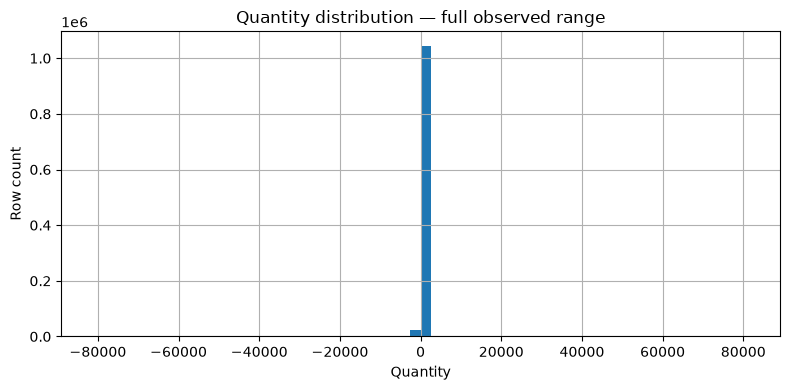


Price summary:


,Price
count,1.067371e+06
mean,4.649388e+00
std,1.235531e+02
min,-5.359436e+04
1%,2.100000e-01
5%,4.200000e-01
25%,1.250000e+00
50%,2.100000e+00
75%,4.150000e+00
95%,9.950000e+00


Price skewness: -69.16473385725457


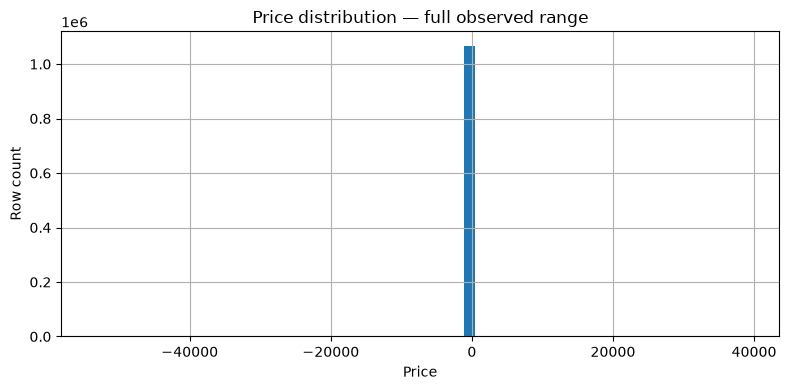

In [20]:
for column in ["Quantity", "Price"]:
    series = pd.to_numeric(df[column], errors="coerce").dropna()
    print(f"\n{column} summary:")
    display(series.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).to_frame())
    print(f"{column} skewness:", series.skew())

    plt.figure(figsize=(8, 4))
    series.hist(bins=60)
    plt.title(f"{column} distribution — full observed range")
    plt.xlabel(column)
    plt.ylabel("Row count")
    plt.tight_layout()
    plt.show()


## 7. Country Coverage

Count records by country to understand geographic coverage.


In [21]:
country_counts = (
    df["Country"].value_counts(dropna=False)
    .rename_axis("Country")
    .reset_index(name="row_count")
)
display(country_counts.head(20))


,Country,row_count
0,United Kingdom,981330
1,EIRE,17866
2,Germany,17624
3,France,14330
4,Netherlands,5140
5,Spain,3811
6,Switzerland,3189
7,Belgium,3123
8,Portugal,2620
9,Australia,1913


## 8. Initial Findings and Limitations

Previously recorded initial checks found:
- 1,067,371 transaction rows across two worksheets.
- 243,007 missing Customer ID values and 4,382 missing Description values.
- 34,335 combined exact duplicate rows.
- 19,494 invoice values starting with `C` and 22,950 negative Quantity rows.
- 6,202 zero Price rows and 5 negative Price rows.
- 352 rows with Quantity greater than 1,000 and 245 rows with Price greater than 1,000.

The notebook recomputes these checks from the local dataset. Review its actual outputs before treating them as reproduced results.

## 9. Relevance to DML

The proposed treatment is Price and the proposed outcome is Quantity. Product, time, and country features may be candidate controls, subject to team review and causal justification.

Observed price–quantity associations do not by themselves establish causality. Returns, cancellations, missing data, confounding, and unavailable promotion or competitor-price information may limit interpretation.

**Status:** Exploratory analysis only. No rows are deleted, no final analytical sample is selected, and no causal model is trained.
